In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_pd = pd.read_json("test.json")
train_pd = pd.read_json("train.json")

# count of malware and goodware
print(test_pd["is_malware"].value_counts(normalize=True)*100)
print(train_pd["is_malware"].value_counts(normalize=True)*100)


is_malware
1    96.264412
0     3.735588
Name: proportion, dtype: float64
is_malware
1    96.257274
0     3.742726
Name: proportion, dtype: float64


# Task1

0        73
1        88
2        79
3        71
4        63
         ..
16320    64
16321    78
16322    84
16323    62
16324    77
Name: api_call_sequence, Length: 16325, dtype: int64
0       98
1       98
2       99
3       85
4       80
        ..
6500    75
6501    83
6502    70
6503    96
6504    78
Name: api_call_sequence, Length: 6505, dtype: int64
              train         test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000


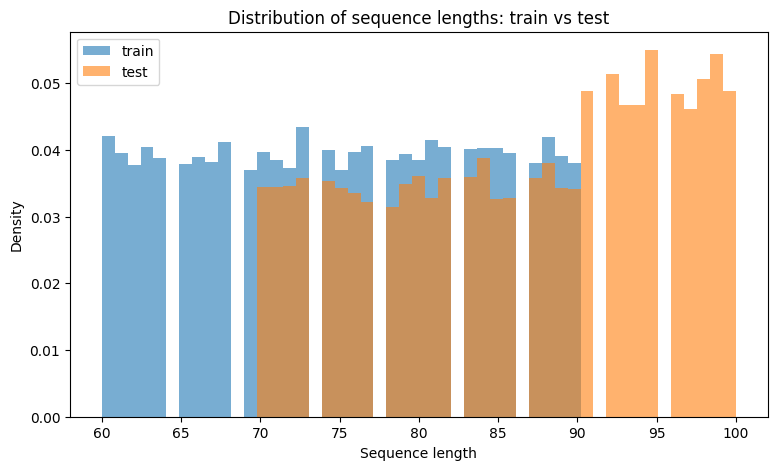

In [ ]:

# sequence lengths
print(train_pd["api_call_sequence"].apply(len))
print(test_pd["api_call_sequence"].apply(len))

train_len = train_pd["api_call_sequence"].apply(len)
test_len = test_pd["api_call_sequence"].apply(len)

# Statistiche per confrontarli numericamente
print(pd.DataFrame({"train": train_len.describe(), "test": test_len.describe()}))

# Istogrammi con bin condivisi e density=True (train e test hanno dimensioni diverse)
bins = np.linspace(min(train_len.min(), test_len.min()),
                   max(train_len.max(), test_len.max()), 50)

plt.figure(figsize=(9, 5))
plt.hist(train_len, bins=bins, alpha=0.6, density=True, label="train")
plt.hist(test_len, bins=bins, alpha=0.6, density=True, label="test")
plt.xlabel("Sequence length")
plt.ylabel("Density")
plt.title("Distribution of sequence lengths: train vs test")
plt.legend()
plt.show()


# Task2

In [ ]:
import scikit-learn as skllm